# Customer Churn: Exploratory Data Analysis

**Purpose.** Understand *who* churns and *when*, before building any model. Every chart answers one written question, and every finding is written as **Observation, Interpretation, Business implication**.

**Reading rule for this notebook.** All findings are *associations* in a single snapshot of 7,043 customers. Nothing here shows that a variable *causes* churn. Where a pattern could be produced by something else, the notebook says so and, where the data allows, checks it.

**Data.** `data/processed/churn_clean.csv`, produced by `src/preprocessing.py` (see `data/processed/cleaning_log.md`). Churn rates are percentages of customers in each group; `n` is the group size. Small groups are noisy, so `n` is always shown.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Locate the project root so the notebook works from notebooks/ or from the repo root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config

FIG_DIR = ROOT / "images" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Restrained palette: red = churn more than 2 points above the overall rate, grey-blue = otherwise.
SLATE, ACCENT, MUTED = "#6B7F99", "#C0504D", "#B8C2CF"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(config.CLEAN_DATA_PATH)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)          # 1 = churned, so mean() = churn rate
OVERALL = df["ChurnFlag"].mean() * 100

# EDA-only groupings. Bin edges are chosen for readability, not optimised; upper edge is inclusive.
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
df["ChargeBand"] = pd.cut(df["MonthlyCharges"], bins=[0, 35, 65, 95, 200], labels=["<=35", "35-65", "65-95", ">95"])

ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
internet = df[df["InternetService"] != "No"]    # add-ons only make sense for customers who have internet
ORDER_CONTRACT = ["Month-to-month", "One year", "Two year"]


def churn_rate_table(data, col):
    t = data.groupby(col, observed=True)["ChurnFlag"].agg(customers="size", churned="sum", churn_rate_pct="mean")
    t["churn_rate_pct"] = (t["churn_rate_pct"] * 100).round(1)
    return t


def plot_rate_bars(ax, table, title, legend=True):
    """Bar per group: red if more than 2 points above the overall churn rate, grey-blue otherwise; n shown on each bar."""
    colors = [ACCENT if r > OVERALL + 2 else MUTED for r in table["churn_rate_pct"]]   # 2-point margin: tiny gaps are not flagged
    bars = ax.bar(table.index.astype(str), table["churn_rate_pct"], color=colors)
    for bar, (_, row) in zip(bars, table.iterrows()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
                f"{row.churn_rate_pct:.1f}%\nn={int(row.customers):,}", ha="center", va="bottom", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.85), zorder=5)
    ax.axhline(OVERALL, color="black", ls="--", lw=1, label=f"Overall {OVERALL:.1f}%")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, table["churn_rate_pct"].max() * 1.3)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(title)
    if legend:
        ax.legend(frameon=False, loc="upper right")


def rate_heatmap(ax, rate, n, title, vmax=60):
    """Heatmap of churn rate with n printed in each cell."""
    labels = rate.round(1).astype(str) + "%\n(n=" + n.map("{:,.0f}".format) + ")"
    sns.heatmap(rate, annot=labels, fmt="", cmap="Reds", vmin=0, vmax=vmax, linewidths=1,
                cbar_kws={"label": "Churn rate (%)"}, ax=ax)
    ax.set_title(title)


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

print(f"{df.shape[0]:,} customers, {df.shape[1] - 3} original columns | overall churn rate {OVERALL:.2f}%")

7,043 customers, 21 original columns | overall churn rate 26.54%


## 1. Baseline: how many customers churn, and how much revenue do they represent?

**Question.** What is the overall churn rate, and does counting customers understate the revenue impact?

In [2]:
summary = pd.Series({"customers": len(df), "churned": int(df["ChurnFlag"].sum()),
                     "churn_rate_pct": round(OVERALL, 2),
                     "accuracy of always predicting 'No' (%)": round(100 - OVERALL, 2)})
display(summary.to_frame("value"))

# Monthly charges are the only revenue field in the data. Currency is not stated by the dataset.
rev = df.groupby("Churn")["MonthlyCharges"].agg(customers="size", total_monthly_charges="sum", avg_monthly_charges="mean").round(2)
rev["share_of_customers_pct"] = (rev["customers"] / rev["customers"].sum() * 100).round(1)
rev["share_of_monthly_charges_pct"] = (rev["total_monthly_charges"] / rev["total_monthly_charges"].sum() * 100).round(1)
display(rev)

,value
customers,7043.00
churned,1869.00
churn_rate_pct,26.54
accuracy of always predicting 'No' (%),73.46


,customers,total_monthly_charges,avg_monthly_charges,share_of_customers_pct,share_of_monthly_charges_pct
Churn,,,,,
No,5174,316985.75,61.27,73.5,69.5
Yes,1869,139130.85,74.44,26.5,30.5


**Observation.** 1,869 of 7,043 customers (26.5%) are labelled `Churn = Yes`. They account for 139,130.85 of 456,116.60 in total monthly charges (30.5%), a larger share than their customer share, because churned customers pay more on average (74.44 vs 61.27 per month).

**Interpretation.** Headcount understates revenue exposure. Also, a model that always predicts "No" would be right 73.5% of the time, so accuracy alone cannot judge a churn model; recall, precision and ROC-AUC are required (as the brief specifies).

**Business implication.** Revenue at Risk should be measured in monthly charges, not customer counts. Caveat: `MonthlyCharges` is the current bill, not lifetime value, and no currency is stated in the dataset.

## 2. Does contract type separate churners from non-churners?

,customers,churned,churn_rate_pct
Contract,,,
Month-to-month,3875,1655,42.7
One year,1473,166,11.3
Two year,1695,48,2.8


,share_of_customers_pct,share_of_churners_pct
Contract,,
Month-to-month,55.0,88.6
One year,20.9,8.9
Two year,24.1,2.6


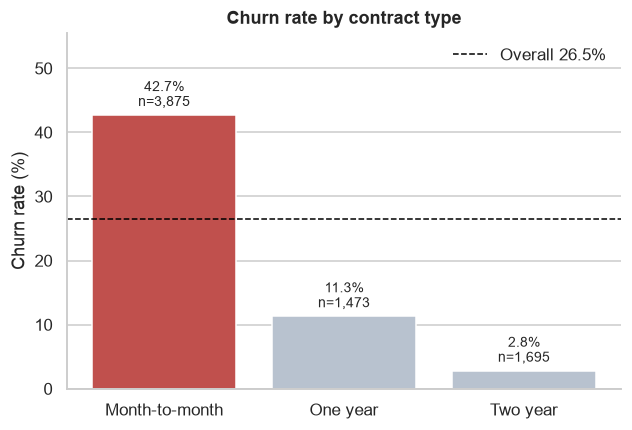

In [3]:
t = churn_rate_table(df, "Contract").loc[ORDER_CONTRACT]
display(t)
share = pd.DataFrame({"share_of_customers_pct": df["Contract"].value_counts(normalize=True) * 100,
                      "share_of_churners_pct": df.loc[df["ChurnFlag"] == 1, "Contract"].value_counts(normalize=True) * 100}).round(1).loc[ORDER_CONTRACT]
display(share)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
plot_rate_bars(ax, t, "Churn rate by contract type")
save(fig, "01_churn_by_contract.png")
plt.show()

**Observation.** Churn is 42.7% on month-to-month, 11.3% on one-year and 2.8% on two-year contracts. Month-to-month customers are 55.0% of the base but 88.6% of churners.

**Interpretation.** Contract type is the strongest single separator in the data (it ranks first in section 9). This is an association. Two things could inflate it without commitment itself reducing churn: (1) customers already inclined to leave may choose month-to-month, and (2) a customer under a fixed term may be unable or unwilling to leave before it ends. The dataset has no contract start/end dates, so these cannot be separated here.

**Business implication.** Month-to-month customers are where most churn sits. Incentives to move customers onto longer terms are a hypothesis worth testing (for example with a controlled pilot), not a proven fix.

## 3. When in the customer lifecycle does churn happen?

,customers,churned,churn_rate_pct
TenureGroup,,,
0-12,2186,1037,47.4
13-24,1024,294,28.7
25-48,1594,325,20.4
49-72,2239,213,9.5


,median,mean
Churn,,
No,38.0,37.6
Yes,10.0,18.0


Share of all churners with tenure <= 12 months: 55.5%


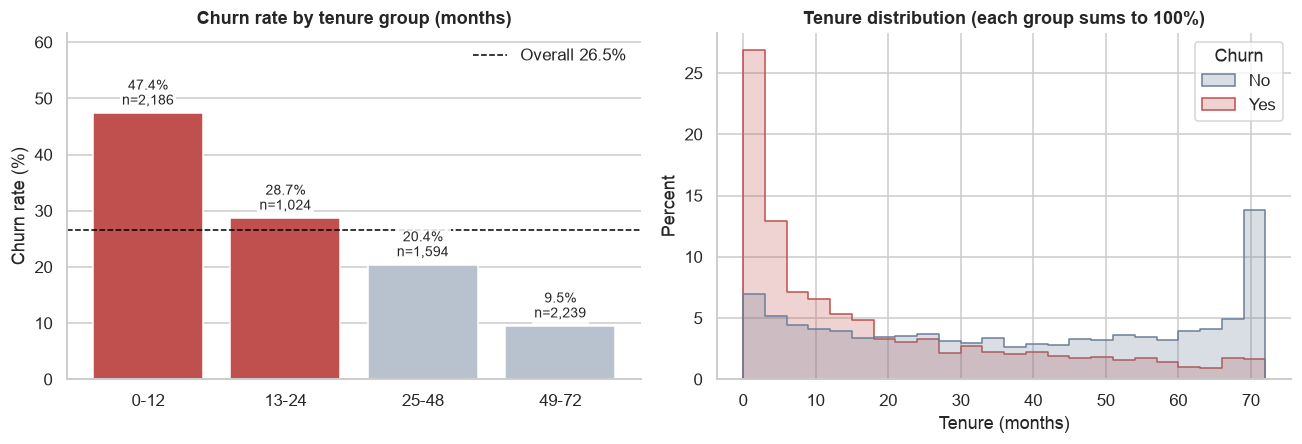

In [4]:
t = churn_rate_table(df, "TenureGroup")
display(t)
display(df.groupby("Churn")["tenure"].agg(median="median", mean="mean").round(1))
early_share = ((df["ChurnFlag"] == 1) & (df["tenure"] <= 12)).sum() / df["ChurnFlag"].sum() * 100
print(f"Share of all churners with tenure <= 12 months: {early_share:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_rate_bars(axes[0], t, "Churn rate by tenure group (months)")
sns.histplot(data=df, x="tenure", hue="Churn", bins=24, element="step", stat="percent", common_norm=False,
             palette={"No": SLATE, "Yes": ACCENT}, ax=axes[1])
axes[1].set_title("Tenure distribution (each group sums to 100%)")
axes[1].set_xlabel("Tenure (months)")
fig.tight_layout()
save(fig, "02_churn_by_tenure.png")
plt.show()

**Observation.** Churn falls steadily with tenure: 47.4% (0-12 months), 28.7% (13-24), 20.4% (25-48) and 9.5% (49-72). Median tenure is 10.0 months for churners and 38.0 for retained customers, and 55.5% of churners left within their first 12 months.

**Interpretation.** Risk is concentrated early. Be careful with the causal reading: tenure for a churner is *how long they stayed before leaving*, so long-tenure customers are by construction people who stayed (survivorship). The 0-12 group also includes the 11 brand-new customers with tenure 0 (all retained).

**Business implication.** The first year is the highest-risk window, which points to onboarding and early-life engagement as places to look. The data cannot say what happens in those months.

## 4. Is the tenure effect just the contract effect in disguise?

**Question.** Contract and tenure are related (long-tenure customers are more often on long contracts). Does churn still fall with tenure *within* a contract type?

TenureGroup,0-12,13-24,25-48,49-72
Contract,,,,
Month-to-month,51.4,37.7,32.9,26.0
One year,10.5,8.1,10.6,12.9
Two year,0.0,0.0,2.2,3.3


TenureGroup,0-12,13-24,25-48,49-72
Contract,,,,
Month-to-month,1994,737,802,342
One year,124,197,518,634
Two year,68,90,274,1263


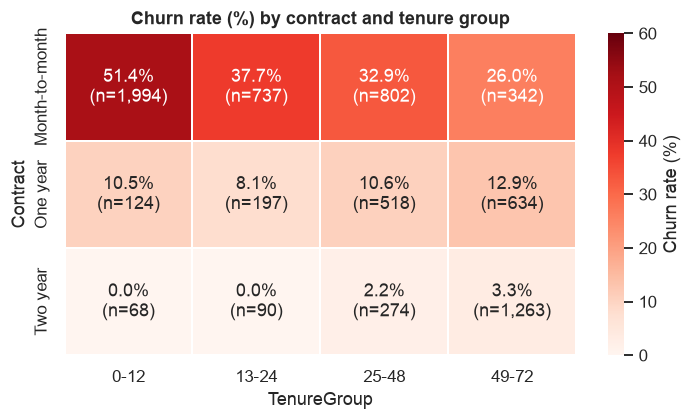

In [5]:
rate = df.pivot_table(index="Contract", columns="TenureGroup", values="ChurnFlag", aggfunc="mean", observed=True).loc[ORDER_CONTRACT] * 100
n = df.pivot_table(index="Contract", columns="TenureGroup", values="ChurnFlag", aggfunc="size", observed=True).loc[ORDER_CONTRACT]
display(rate.round(1))
display(n)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
rate_heatmap(ax, rate, n, "Churn rate (%) by contract and tenure group")
save(fig, "03_contract_by_tenure.png")
plt.show()

**Observation.** Within month-to-month contracts, churn still falls with tenure, from 51.4% to 26.0%. Even long-tenure month-to-month customers churn at about the overall rate. Two-year customers show 0.0% churn in their first 24 months (n=68 and 90).

**Interpretation.** Both variables carry information: tenure matters within month-to-month, and contract matters at every tenure. The zero churn on early two-year contracts is consistent with customers being locked in until the term ends (a hypothesis; the data has no term dates).

**Business implication.** A model should use both. Retention effort aimed only at "new customers" would miss the month-to-month customers who stay for years and still churn at a high rate.

## 5. Do internet service type and add-on services relate to churn?

**Question.** Fiber customers pay more. Is their higher churn just a price effect? And do support/security add-ons matter *among customers who have internet*?

,customers,churned,churn_rate_pct
InternetService,,,
No,1526,113,7.4
DSL,2421,459,19.0
Fiber optic,3096,1297,41.9


Mean monthly charges by internet service:


,avg_monthly_charges
InternetService,
DSL,58.1
Fiber optic,91.5
No,21.1


,churn_pct_without,churn_pct_with,customers_without,customers_with,gap_pts
service,,,,,
OnlineSecurity,41.8,14.6,3498,2019,27.2
TechSupport,41.6,15.2,3473,2044,26.4
OnlineBackup,39.9,21.5,3088,2429,18.4
DeviceProtection,39.1,22.5,3095,2422,16.6
StreamingMovies,33.7,29.9,2785,2732,3.8
StreamingTV,33.5,30.1,2810,2707,3.4


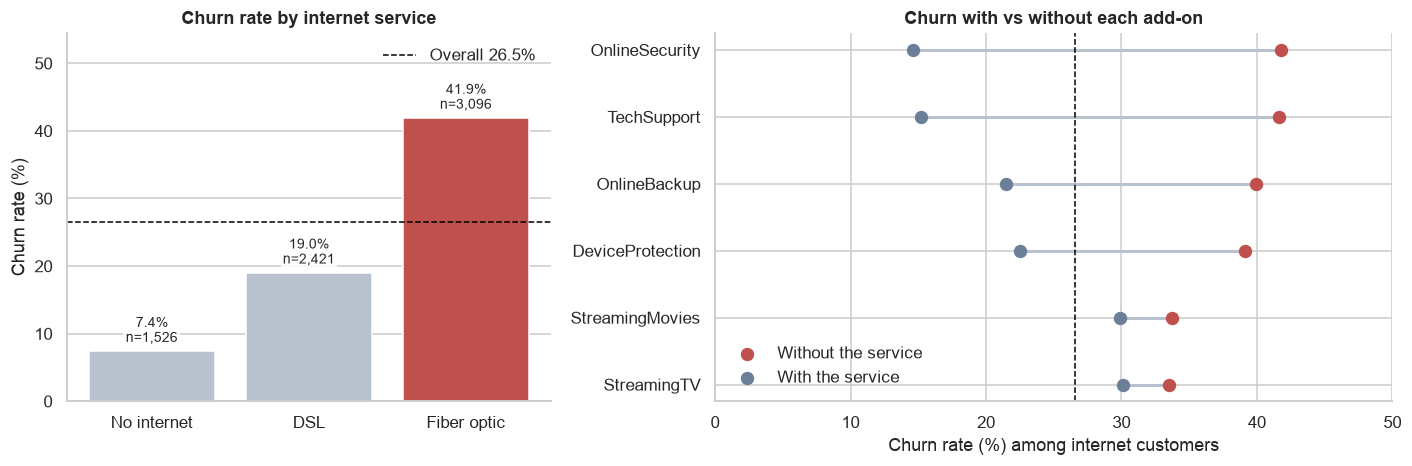

In [6]:
ORDER_NET = ["No", "DSL", "Fiber optic"]
t_net = churn_rate_table(df, "InternetService").loc[ORDER_NET]
display(t_net)
print("Mean monthly charges by internet service:")
display(df.groupby("InternetService")["MonthlyCharges"].mean().round(1).to_frame("avg_monthly_charges"))

# Add-ons are compared only among internet customers, otherwise 'No internet service' (7.4% churn) pollutes the 'No' group.
rows = []
for c in ADDONS:
    r = internet.groupby(c)["ChurnFlag"].mean() * 100
    rows.append({"service": c, "churn_pct_without": r["No"], "churn_pct_with": r["Yes"],
                 "customers_without": int((internet[c] == "No").sum()), "customers_with": int((internet[c] == "Yes").sum())})
addon_tbl = pd.DataFrame(rows).set_index("service").round(1)
addon_tbl["gap_pts"] = (addon_tbl["churn_pct_without"] - addon_tbl["churn_pct_with"]).round(1)
display(addon_tbl.sort_values("gap_pts", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.4]})
plot_rate_bars(axes[0], t_net.rename(index={"No": "No internet"}), "Churn rate by internet service")
plot_df = addon_tbl.sort_values("gap_pts")
y = np.arange(len(plot_df))
axes[1].hlines(y, plot_df["churn_pct_with"], plot_df["churn_pct_without"], color=MUTED, lw=2)
axes[1].scatter(plot_df["churn_pct_without"], y, color=ACCENT, s=60, label="Without the service", zorder=3)
axes[1].scatter(plot_df["churn_pct_with"], y, color=SLATE, s=60, label="With the service", zorder=3)
axes[1].set_yticks(y, plot_df.index)
axes[1].axvline(OVERALL, color="black", ls="--", lw=1)
axes[1].set_xlabel("Churn rate (%) among internet customers")
axes[1].set_title("Churn with vs without each add-on")
axes[1].set_xlim(0, 50)
axes[1].legend(frameon=False, loc="lower left")
fig.tight_layout()
save(fig, "04_internet_and_addons.png")
plt.show()

In [7]:
# Confounding check 1: is fiber's higher churn just higher prices? Compare internet types inside the same price band.
rate_ib = (df.pivot_table(index="InternetService", columns="ChargeBand", values="ChurnFlag", aggfunc="mean", observed=True) * 100).round(1)
n_ib = df.pivot_table(index="InternetService", columns="ChargeBand", values="ChurnFlag", aggfunc="size", observed=True)
print("Churn rate (%) by internet service and monthly-charge band (blank = no customers in that cell)")
display(rate_ib)
print("Customers in each cell")
display(n_ib)

# Confounding check 2: does the tech-support gap survive inside the fiber group?
display(churn_rate_table(df[df["InternetService"] == "Fiber optic"], "TechSupport"))

Churn rate (%) by internet service and monthly-charge band (blank = no customers in that cell)


ChargeBand,<=35,35-65,65-95,>95
InternetService,,,,
DSL,36.4,23.1,7.1,NaN
Fiber optic,NaN,NaN,48.8,32.3
No,7.4,NaN,NaN,NaN


Customers in each cell


ChargeBand,<=35,35-65,65-95,>95
InternetService,,,,
DSL,209.0,1409.0,803.0,NaN
Fiber optic,NaN,NaN,1801.0,1295.0
No,1526.0,NaN,NaN,NaN


,customers,churned,churn_rate_pct
TechSupport,,,
No,2230,1101,49.4
Yes,866,196,22.6


**Observation.** Fiber churns at 41.9% versus 19.0% for DSL and 7.4% for customers without internet. Fiber customers pay more (average 91.5 vs 58.1 for DSL), but inside the 65-95 price band, which both services share, fiber churns at 48.8% (n=1,801) against 7.1% for DSL (n=803). Among internet customers, those *without* OnlineSecurity churn at 41.8% versus 14.6% with it; for TechSupport it is 41.6% vs 15.2%. OnlineBackup and DeviceProtection show smaller gaps, and StreamingTV/Movies show almost none. The tech-support gap persists inside fiber (49.4% without vs 22.6% with).

**Interpretation.** Price alone does not explain fiber's churn, because the gap remains in a shared price band (the two services overlap in only that one band, so this is a partial check). Support and security add-ons are associated with much lower churn, while entertainment add-ons are not. Possible explanations include better service experience, deeper engagement, or simply that customers who buy support differ from those who do not (self-selection). The data cannot distinguish these, and it has no information on outages, tickets or competitors.

**Business implication.** Two hypotheses to investigate: (1) fiber customers may have an experience or competition issue the dataset cannot show; (2) offering security/support bundles to at-risk internet customers might reduce churn, but this needs a controlled test before assuming that adding the service *causes* retention.

## 6. How do monthly and total charges relate to churn?

MonthlyCharges        TotalCharges        
                mean median         mean  median
Churn                                           
No              61.0   64.0       2550.0  1680.0
Yes             74.0   80.0       1532.0   704.0

,customers,churned,churn_rate_pct
ChargeBand,,,
<=35,1735,189,10.9
35-65,1409,326,23.1
65-95,2604,936,35.9
>95,1295,418,32.3


Correlation of tenure with TotalCharges: 0.826


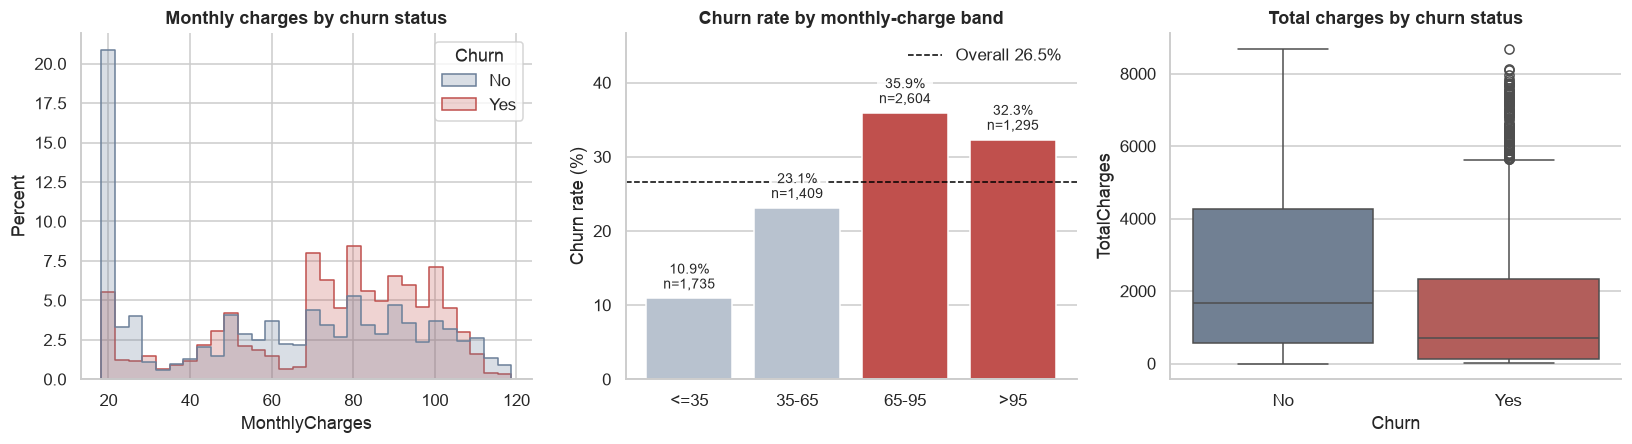

In [8]:
display(df.groupby("Churn")[["MonthlyCharges", "TotalCharges"]].agg(["mean", "median"]).round(0))
cb_tbl = churn_rate_table(df, "ChargeBand")
display(cb_tbl)
print(f"Correlation of tenure with TotalCharges: {df['tenure'].corr(df['TotalCharges']):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, element="step", stat="percent", common_norm=False,
             palette={"No": SLATE, "Yes": ACCENT}, ax=axes[0])
axes[0].set_title("Monthly charges by churn status")
plot_rate_bars(axes[1], cb_tbl, "Churn rate by monthly-charge band")
sns.boxplot(data=df, x="Churn", y="TotalCharges", palette={"No": SLATE, "Yes": ACCENT}, hue="Churn", legend=False, ax=axes[2])
axes[2].set_title("Total charges by churn status")
fig.tight_layout()
save(fig, "05_charges.png")
plt.show()

**Observation.** Churned customers pay more per month on average (74.4 vs 61.3), but the relationship is not a straight line: churn is 10.9% in the lowest band, 23.1% and 35.9% in the middle bands, then 32.3% in the highest band. Churners have much lower TotalCharges (mean 1,532 vs 2,550), and TotalCharges correlates 0.826 with tenure.

**Interpretation.** Monthly charge is tangled up with service type (the top band is entirely fiber, see section 5), so it is not a clean "price sensitivity" signal. Lower TotalCharges among churners mostly restates that they have shorter tenures, not an independent pricing effect.

**Business implication.** Do not read "low total charges means churn" as a pricing insight. For modelling, `TotalCharges` is largely redundant with tenure and monthly charge, so collinearity needs deliberate handling; section 11 quantifies it, including how closely the services determine `MonthlyCharges`, and records the decisions. The band edges here are readability choices, not optimised thresholds.

## 7. Do payment method and billing type relate to churn?

,customers,churned,churn_rate_pct
PaymentMethod,,,
Electronic check,2365,1071,45.3
Mailed check,1612,308,19.1
Bank transfer (automatic),1544,258,16.7
Credit card (automatic),1522,232,15.2


,customers,churned,churn_rate_pct
PaperlessBilling,,,
No,2872,469,16.3
Yes,4171,1400,33.6


Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Electronic check,53.7,18.4,7.7
Mailed check,31.6,6.8,0.8
Bank transfer (automatic),34.1,9.7,3.4
Credit card (automatic),32.8,10.3,2.2


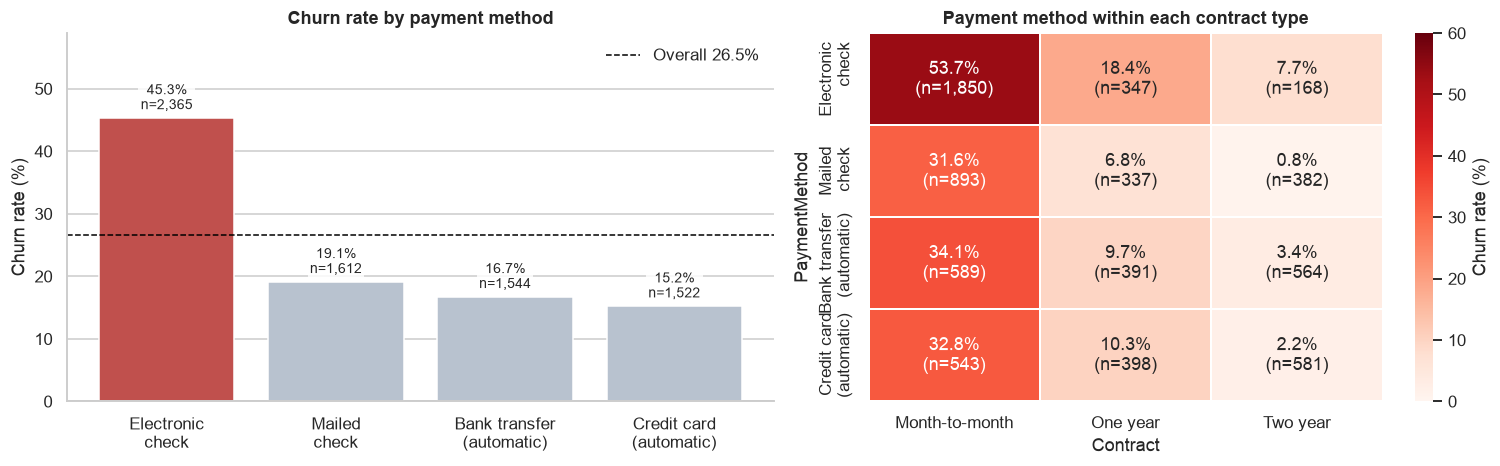

In [9]:
ORDER_PAY = ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"]
t_pay = churn_rate_table(df, "PaymentMethod").loc[ORDER_PAY]
display(t_pay)
display(churn_rate_table(df, "PaperlessBilling"))

rate = df.pivot_table(index="PaymentMethod", columns="Contract", values="ChurnFlag", aggfunc="mean").loc[ORDER_PAY, ORDER_CONTRACT] * 100
n = df.pivot_table(index="PaymentMethod", columns="Contract", values="ChurnFlag", aggfunc="size").loc[ORDER_PAY, ORDER_CONTRACT]
display(rate.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
labels = {"Bank transfer (automatic)": "Bank transfer\n(automatic)", "Credit card (automatic)": "Credit card\n(automatic)",
          "Electronic check": "Electronic\ncheck", "Mailed check": "Mailed\ncheck"}
plot_rate_bars(axes[0], t_pay.rename(index=labels), "Churn rate by payment method")
rate_heatmap(axes[1], rate.rename(index=labels), n.rename(index=labels), "Payment method within each contract type")
fig.tight_layout()
save(fig, "06_payment_method.png")
plt.show()

**Observation.** Electronic-check customers churn at 45.3%, versus 19.1% for mailed check, 16.7% for automatic bank transfer and 15.2% for automatic credit card. The gap persists inside month-to-month contracts (53.7% for electronic check vs 31.6-34.1% for the others). Paperless billing is 33.6% vs 16.3% without.

**Interpretation.** Payment method is associated with churn even after accounting for contract type. Electronic check is the only manual electronic method here, so the pattern may reflect payment friction, a different customer segment, or something else, and the direction cannot be determined from this data.

**Business implication.** A testable idea is encouraging automatic payment among electronic-check customers, with the caveat that switching payment method may not change the underlying risk if the method is only a marker for other differences.

## 8. Do demographics matter?

,customers,churned,churn_rate_pct
SeniorCitizen,,,
No,5901,1393,23.6
Yes,1142,476,41.7


,customers,churned,churn_rate_pct
Partner,,,
No,3641,1200,33.0
Yes,3402,669,19.7


,customers,churned,churn_rate_pct
Dependents,,,
No,4933,1543,31.3
Yes,2110,326,15.5


,customers,churned,churn_rate_pct
gender,,,
Female,3488,939,26.9
Male,3555,930,26.2


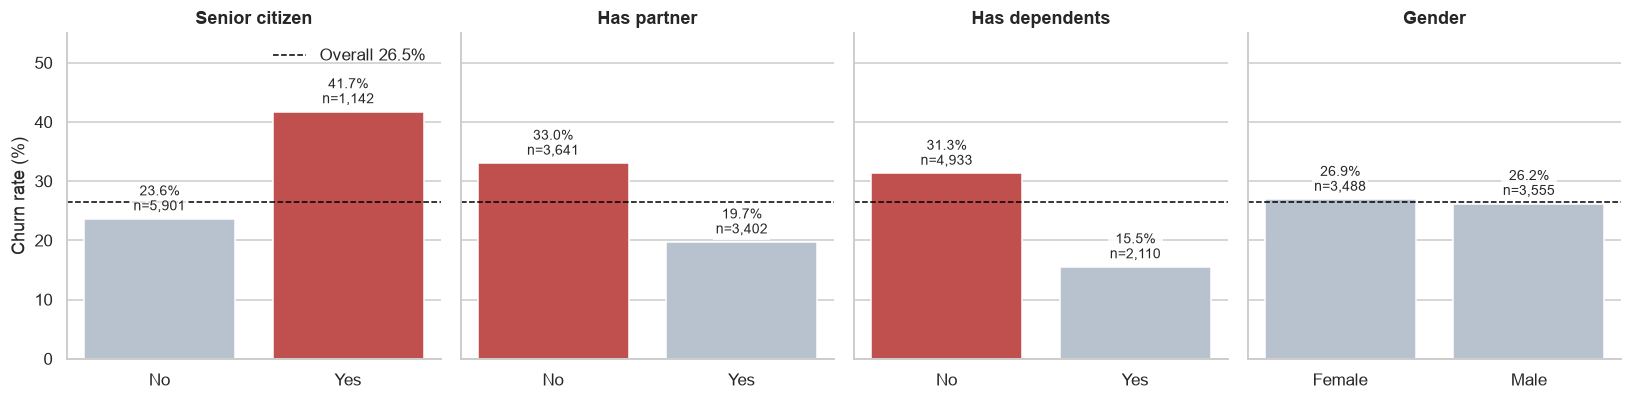

Contract,Month-to-month,One year,Two year
SeniorCitizen,,,
0,39.6,10.7,2.7
1,54.6,15.3,4.1


,customers,churned,churn_rate_pct
No,682,170,24.9
Yes,6361,1699,26.7
No,3390,849,25.0
No phone service,682,170,24.9
Yes,2971,850,28.6


In [10]:
panels = [("SeniorCitizen", "Senior citizen"), ("Partner", "Has partner"), ("Dependents", "Has dependents"), ("gender", "Gender")]
demo = df.assign(SeniorCitizen=df["SeniorCitizen"].map({0: "No", 1: "Yes"}))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for i, (ax, (col, title)) in enumerate(zip(axes, panels)):
    order = ["Female", "Male"] if col == "gender" else ["No", "Yes"]
    t = churn_rate_table(demo, col).loc[order]
    plot_rate_bars(ax, t, title, legend=(i == 0))
    if i:
        ax.set_ylabel("")
    display(t)
axes[0].set_ylim(0, 55)            # shared axis (sharey=True): set once so no panel clips another's bars
fig.tight_layout()
save(fig, "07_demographics.png")
plt.show()

# Does the senior-citizen gap survive within contract type?
display((df.pivot_table(index="SeniorCitizen", columns="Contract", values="ChurnFlag", aggfunc="mean")[ORDER_CONTRACT] * 100).round(1))
display(pd.concat([churn_rate_table(df, "PhoneService"), churn_rate_table(df, "MultipleLines")]))

**Observation.** Senior citizens churn at 41.7% vs 23.6%. Customers without a partner churn at 33.0% vs 19.7%, and without dependents at 31.3% vs 15.5%. Gender shows essentially no difference (26.9% vs 26.2%). Phone service (24.9% vs 26.7%) and multiple lines are also near-flat. The senior-citizen gap persists within every contract type (for example 54.6% vs 39.6% on month-to-month).

**Interpretation.** Household and age variables carry some signal; gender carries none. These variables describe who the customer is, not anything the company controls.

**Business implication.** Gender shows no association with churn; section 11 tests whether removing it affects model performance. Age-related variables should be used with care: treating customers differently by age (pricing, offers) can raise fairness and regulatory questions, so using them for targeting is a deliberate decision, not a default.

## 9. Which variables separate churners best? (effect size, not p-values)

**Why Cramér's V.** With 7,000+ rows almost every difference is "statistically significant", so p-values cannot rank variables. Cramér's V measures how strongly a categorical variable is associated with churn on a 0 (none) to 1 (perfect) scale. It ranks *association strength only*: it ignores overlap between variables, so two redundant variables can both rank high.

,cramers_v
Contract,0.410
TenureGroup (binned),0.349
InternetService,0.322
PaymentMethod,0.303
OnlineSecurity,0.281
TechSupport,0.274
ChargeBand (binned),0.228
OnlineBackup,0.196
PaperlessBilling,0.192
DeviceProtection,0.177


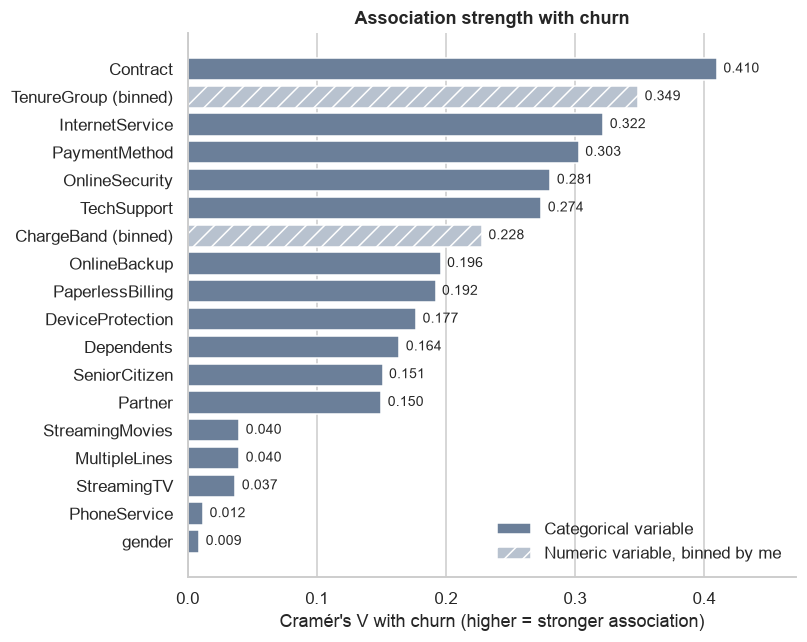

In [11]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))))

CATEGORICAL = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
               *ADDONS, "Contract", "PaperlessBilling", "PaymentMethod"]
scores = {}
for col in CATEGORICAL:
    data = internet if col in ADDONS else df           # add-ons: internet customers only (see section 5)
    scores[col] = cramers_v(data[col], data["Churn"])
scores["TenureGroup (binned)"] = cramers_v(df["TenureGroup"], df["Churn"])
scores["ChargeBand (binned)"] = cramers_v(df["ChargeBand"], df["Churn"])
v = pd.Series(scores).sort_values(ascending=False).round(3)
display(v.to_frame("cramers_v"))

fig, ax = plt.subplots(figsize=(7.5, 6))
from matplotlib.patches import Patch
bars = ax.barh(v.index[::-1], v.values[::-1], color=SLATE)
for bar, name in zip(bars, v.index[::-1]):
    if "binned" in name:                      # binned numeric variables depend on my bin choices
        bar.set_facecolor(MUTED); bar.set_hatch("//"); bar.set_edgecolor("white")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(facecolor=SLATE, label="Categorical variable"),
                   Patch(facecolor=MUTED, hatch="//", edgecolor="white", label="Numeric variable, binned by me")],
          frameon=False, loc="lower right")
ax.set_xlabel("Cramér's V with churn (higher = stronger association)")
ax.set_title("Association strength with churn")
for i, val in enumerate(v.values[::-1]):
    ax.text(val + 0.005, i, f"{val:.3f}", va="center", fontsize=9)
ax.set_xlim(0, v.max() * 1.15)
fig.tight_layout()
save(fig, "08_association_strength.png")
plt.show()

**Observation.** The five strongest associations are: Contract (0.410), TenureGroup (binned) (0.349), InternetService (0.322), PaymentMethod (0.303), OnlineSecurity (0.281). The five weakest are gender (0.009), PhoneService (0.012), StreamingTV (0.037), MultipleLines (0.040) and StreamingMovies (0.040).

**Interpretation.** Commitment (contract, tenure), internet type, payment method and support/security services dominate. Add-ons are scored among internet customers only; scoring them across all customers would have made the streaming services look moderately associated (V about 0.23), purely because the 'No internet service' level has a low churn rate of its own. Many of these overlap (fiber customers lack add-ons more often; month-to-month customers have short tenure), so this ranking should not be read as five independent drivers. Binned numeric variables (grey) depend on my bin choices and are not strictly comparable to the categorical ones.

**Business implication.** The signal is concentrated in how customers are committed and served, not who they are. Only a multivariate model can show how much of this signal is shared between variables.

## 10. EDA hypotheses for feature engineering

Association tables can suggest features that *might* help a model, but they cannot show that a model benefits from them. Everything in this section is therefore a **hypothesis**, except the two checks that found redundancy or no signal. Section 11 tests the hypotheses with a model-based ablation; where the two sections differ, section 11 is the evidence.

In [12]:
# (a) Count of add-ons among internet customers
internet = internet.assign(n_addons=(internet[ADDONS] == "Yes").sum(axis=1),
                           n_protective=(internet[["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]] == "Yes").sum(axis=1))
display(churn_rate_table(internet, "n_addons").rename_axis("add-ons taken (of 6)"))
display(churn_rate_table(internet, "n_protective").rename_axis("protective add-ons taken (of 4)"))

# (b) Automatic payment flag
df["AutoPay"] = df["PaymentMethod"].str.contains("automatic")
display(churn_rate_table(df, "AutoPay"))

# (c) Is 'AverageMonthlyValue' (TotalCharges / tenure) new information, or a copy of MonthlyCharges?
has_history = df[df["tenure"] > 0].copy()
has_history["AverageMonthlyValue"] = has_history["TotalCharges"] / has_history["tenure"]
print(f"Correlation of MonthlyCharges with TotalCharges/tenure: {has_history['MonthlyCharges'].corr(has_history['AverageMonthlyValue']):.4f}")

# (d) Does the *gap* between current and historical average charge (a price-change proxy) relate to churn?
has_history["ChargeDrift"] = pd.cut((has_history["MonthlyCharges"] / has_history["AverageMonthlyValue"] - 1) * 100,
                                    [-100, -5, 5, 100], labels=["lower_now (<-5%)", "within_5pct", "higher_now (>+5%)"])
display(churn_rate_table(has_history, "ChargeDrift"))

,customers,churned,churn_rate_pct
add-ons taken (of 6),,,
0,693,362,52.2
1,966,442,45.8
2,1033,370,35.8
3,1118,306,27.4
4,852,190,22.3
5,571,71,12.4
6,284,15,5.3


,customers,churned,churn_rate_pct
protective add-ons taken (of 4),,,
0,1267,718,56.7
1,1467,570,38.9
2,1372,326,23.8
3,941,117,12.4
4,470,25,5.3


,customers,churned,churn_rate_pct
AutoPay,,,
False,3977,1379,34.7
True,3066,490,16.0


Correlation of MonthlyCharges with TotalCharges/tenure: 0.9962


,customers,churned,churn_rate_pct
ChargeDrift,,,
lower_now (<-5%),625,162,25.9
within_5pct,5661,1495,26.4
higher_now (>+5%),746,212,28.4


**What the EDA evidence shows.**

| Candidate | EDA evidence | Status |
|---|---|---|
| `ProtectiveAddOnCount` (count of the four protective add-ons) | Among internet customers, churn falls steadily from 56.7% with none to 5.3% with all four. | Hypothesis: a summary count may help a model. Tested in section 11. |
| `AutoPay` (automatic card or bank payment) | 16.0% churn vs 34.7% for manual methods. | Hypothesis. Tested in section 11. |
| `TenureGroup` (bands of tenure) | Strong, non-linear fall in churn with tenure (section 3). | Hypothesis: bands may help linear models. Tested in section 11. |
| `AverageMonthlyValue` (`TotalCharges / tenure`) | Correlates 0.9962 with `MonthlyCharges`: almost a copy. | **EDA finding, not built.** It adds no information. The project brief suggested it; the data does not support it. |
| Charge drift (current vs historical average bill) | Churn is 25.9% / 26.4% / 28.4% across the three groups: essentially flat. | **EDA finding, not built.** No evidence of a price-change signal. |
| Low-signal columns: `gender`, `PhoneService`, `MultipleLines`, `StreamingTV`, `StreamingMovies` | Each shows almost no association with churn on its own (section 9). | Whether removing them is safe is a *model* question. Answered in section 11, not here. |

## 11. Feature Selection and Ablation Results

Section 10 produced hypotheses from association tables. Whether a feature improves a model is a different question, and this section answers it with a controlled experiment. Section 10 is hypothesis; this section is evidence.

**Method.** [`src/feature_ablation.py`](../src/feature_ablation.py) trains two models (logistic regression and gradient boosting, default settings, seed 42) on each feature configuration and scores them with repeated stratified cross-validation (5 folds x 3 repeats) using ROC-AUC. The data is the **training split only** (stratified 80/20 split from `make_train_test_split`; 5,634 training rows). The held-out test split is never used, and **this notebook reports no test-set results**. Every configuration is scored on identical folds, so each `delta_auc` is a paired difference against the configuration in the `vs` column (A = base features; E = base plus the three engineered features; I = A without `TotalCharges` and `gender`; L = I without `MonthlyCharges`, the adopted set).

**Reading the numbers.** The standard errors are optimistic, because repeated-CV folds overlap in their training data. As a working rule of thumb (not a statistical test), differences below about 0.002 AUC are treated as ties. The authoritative record is [`output/feature_ablation.md`](../output/feature_ablation.md); this notebook reads the matching `.csv`. The pipeline is implemented in [`src/feature_engineering.py`](../src/feature_engineering.py), and its leakage and behaviour checks live in [`tests/test_feature_engineering.py`](../tests/test_feature_engineering.py) (run `python -m pytest`).

In [13]:
ABLATION_CSV = ROOT / "output" / "feature_ablation.csv"
if not ABLATION_CSV.exists():
    raise FileNotFoundError("Run `python -m src.feature_ablation` first; it writes output/feature_ablation.csv.")

ablation = pd.read_csv(ABLATION_CSV)
columns = ["configuration", "mean_auc", "std_auc", "vs", "delta_auc", "delta_se"]
for model_name, group in ablation.groupby("model", sort=False):
    print(model_name)
    display(group[columns].set_index("configuration").round(4))

Logistic Regression


,mean_auc,std_auc,vs,delta_auc,delta_se
configuration,,,,,
A base features only,0.8462,0.0121,NaN,NaN,NaN
B A + TenureGroup,0.8465,0.0122,A,0.0004,0.0005
C A + ProtectiveAddOnCount,0.8462,0.0121,A,0.0000,0.0000
D A + AutoPay,0.8461,0.0121,A,-0.0000,0.0000
E A + all three engineered,0.8465,0.0122,A,0.0004,0.0005
F A - five low-signal columns,0.8441,0.0115,A,-0.0021,0.0006
G A - gender,0.8465,0.0121,A,0.0004,0.0001
H A - TotalCharges,0.8450,0.0120,A,-0.0012,0.0003
I A - TotalCharges - gender,0.8453,0.0120,A,-0.0008,0.0003


Gradient Boosting


,mean_auc,std_auc,vs,delta_auc,delta_se
configuration,,,,,
A base features only,0.8471,0.0137,NaN,NaN,NaN
B A + TenureGroup,0.8469,0.0136,A,-0.0002,0.0001
C A + ProtectiveAddOnCount,0.8475,0.0135,A,0.0004,0.0003
D A + AutoPay,0.8469,0.0137,A,-0.0002,0.0001
E A + all three engineered,0.8479,0.0134,A,0.0008,0.0004
F A - five low-signal columns,0.8461,0.0132,A,-0.0010,0.0006
G A - gender,0.8473,0.0134,A,0.0002,0.0002
H A - TotalCharges,0.8475,0.0135,A,0.0004,0.0004
I A - TotalCharges - gender,0.8479,0.0133,A,0.0008,0.0004


In [14]:
# TotalCharges: how redundant is it? Variance inflation factor (VIF) = 1 / (1 - R^2), where R^2 comes from
# regressing one numeric column on the other two. Common rule of thumb: roughly 5-10 or more signals problematic collinearity.
from sklearn.linear_model import LinearRegression

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
vif = {}
for col in numeric_cols:
    others = [c for c in numeric_cols if c != col]
    r2 = LinearRegression().fit(df[others], df[col]).score(df[others], df[col])
    vif[col] = 1 / (1 - r2)
display(pd.Series(vif).round(2).to_frame("VIF"))

billed = df[df["tenure"] > 0]          # tenure 0 would divide by zero
ratio = billed["TotalCharges"] / (billed["tenure"] * billed["MonthlyCharges"])
print(f"TotalCharges / (tenure x MonthlyCharges): median {ratio.median():.3f}, 5th-95th percentile {ratio.quantile(.05):.3f} to {ratio.quantile(.95):.3f}")

,VIF
tenure,5.84
MonthlyCharges,3.22
TotalCharges,9.51


TotalCharges / (tenure x MonthlyCharges): median 1.000, 5th-95th percentile 0.924 to 1.075


In [15]:
# MonthlyCharges: how much of the monthly bill do the other model inputs already explain?
# R^2 from regressing MonthlyCharges on every other column the model would see (services, contract, tenure, ...), training rows only.
from src.feature_engineering import DEFAULT_DROP as _ADOPTED_DROP, add_engineered_features, build_pipeline, build_preprocessor, make_train_test_split
from src.interpretation import odds_ratio_table
from sklearn.linear_model import LogisticRegression

X_tr_all, _, y_tr_all, _ = make_train_test_split(pd.read_csv(config.CLEAN_DATA_PATH))
all_inputs = build_preprocessor(scale_numeric=False, drop=()).fit(add_engineered_features(X_tr_all))
Z = all_inputs.transform(add_engineered_features(X_tr_all))
others = Z.drop(columns=["MonthlyCharges"])
r2 = LinearRegression().fit(others, Z["MonthlyCharges"]).score(others, Z["MonthlyCharges"])
print(f"R^2 of MonthlyCharges on all other model inputs: {r2:.4f} (VIF = {1 / (1 - r2):.0f})")

# What that redundancy does to a logistic regression: odds ratios with and without MonthlyCharges, weak (C=10) and stronger (C=0.3) regularisation.
rows = []
for label, drop in [("with MonthlyCharges", ("TotalCharges", "gender")), ("without MonthlyCharges (adopted)", _ADOPTED_DROP)]:
    for C in (0.3, 10):
        pipe = build_pipeline(LogisticRegression(C=C, max_iter=5000, random_state=config.RANDOM_SEED), drop=drop).fit(X_tr_all, y_tr_all)
        t = odds_ratio_table(pipe).set_index(["feature", "comparison"])["odds_ratio"]
        rows.append({"feature set": label, "C": C, "Fiber vs DSL": t[("InternetService", "Fiber optic vs DSL")],
                     "OnlineSecurity Yes vs No": t[("OnlineSecurity", "Yes vs No")], "StreamingTV Yes vs No": t[("StreamingTV", "Yes vs No")]})
display(pd.DataFrame(rows).round(2))

R^2 of MonthlyCharges on all other model inputs: 0.9988 (VIF = 862)


,feature set,C,Fiber vs DSL,OnlineSecurity Yes vs No,StreamingTV Yes vs No
0,with MonthlyCharges,0.3,2.14,0.66,1.24
1,with MonthlyCharges,10.0,9.06,0.87,2.22
2,without MonthlyCharges (adopted),0.3,2.45,0.68,1.32
3,without MonthlyCharges (adopted),10.0,2.51,0.67,1.32


In [16]:
# The final model input, built by the project's own pipeline code and fitted on training rows only.
from src.feature_engineering import (DEFAULT_DROP, DEFAULT_ENGINEERED, add_engineered_features,
                                     build_preprocessor, make_train_test_split)

clean = pd.read_csv(config.CLEAN_DATA_PATH)      # fresh copy: the working `df` above carries extra EDA columns
X_train, X_test, y_train, y_test = make_train_test_split(clean)
preprocessor = build_preprocessor().fit(add_engineered_features(X_train))
model_columns = list(preprocessor.get_feature_names_out())

print(f"Training rows: {len(X_train):,} | held-out rows (not used in this notebook): {len(X_test):,}")
print(f"Engineered features in the model by default: {list(DEFAULT_ENGINEERED) or 'none'}")
print(f"Columns dropped by default: {list(DEFAULT_DROP)}")
print(f"Model input: {len(model_columns)} columns")
print(model_columns)

Training rows: 5,634 | held-out rows (not used in this notebook): 1,409
Engineered features in the model by default: none
Columns dropped by default: ['TotalCharges', 'gender', 'MonthlyCharges']
Model input: 23 columns
['tenure', 'SeniorCitizen', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


### Decision 1: the engineered features are not in the final feature set

Adding `TenureGroup`, `ProtectiveAddOnCount` and `AutoPay`, one at a time (configurations B, C, D) or all together (E), changed ROC-AUC by at most 0.0008. For all three together the change is +0.0004 for logistic regression and +0.0008 for gradient boosting, inside the noise. The likely reason is that both models can already learn these patterns from the raw columns: logistic regression can combine add-on and payment indicators itself, and gradient boosting finds tenure cut-points on its own.

With no demonstrated benefit, the final feature set does not carry them. They add complexity, and for logistic regression they duplicate information already in the one-hot columns, which makes coefficients harder to read. **The section 10 hypotheses are therefore not supported as predictive features.** The patterns behind them (sections 5 and 7) remain valid descriptive findings. The code stays in `add_engineered_features` and can be switched on with `build_preprocessor(engineered=...)` for descriptive use or re-testing.

### Decision 2: only `gender` is dropped from the five low-signal columns

Section 9 found five variables with almost no individual association with churn. Weak association on its own does not prove a variable is useless inside a model, so it was tested rather than assumed (configurations F and G, against A):

- **Dropping all five together** changed AUC by -0.0021 (logistic regression) and -0.0010 (gradient boosting). The logistic-regression drop is at the 0.002 threshold; the gradient-boosting drop is inside the noise. Neither model shows that removing the group helps, and logistic regression hints that the columns carry a little combined signal, so `PhoneService`, `MultipleLines`, `StreamingTV` and `StreamingMovies` are kept. This is suggestive, not conclusive, for gradient boosting.
- **Dropping `gender` alone** changed AUC by +0.0004 (logistic regression) and +0.0002 (gradient boosting): no accuracy cost. It is removed because it has no association with churn (section 8, Cramér's V 0.009) and keeping a protected attribute in a retention model carries a fairness downside with no demonstrated benefit.

### Decision 3 (separate): `TotalCharges` is dropped, for collinearity and not for accuracy

`TotalCharges` is largely `tenure x MonthlyCharges`: the ratio has a median of 1.000 (5th-95th percentile 0.924 to 1.075), it correlates 0.826 with tenure (section 6), and its variance inflation factor is **9.51** (tenure 5.84, `MonthlyCharges` 3.22). Collinear inputs make linear-model coefficients unstable and hard to interpret, which matters because those coefficients will be read as part of model interpretation.

The accuracy cost is within noise but not zero: removing it from the base features changed AUC by -0.0012 for logistic regression and +0.0004 for gradient boosting (configuration H). With the engineered features present, the logistic-regression change shrinks to -0.0002 (configuration J), which suggests `TotalCharges` was acting as a crude non-linear tenure term. Because the engineered features are excluded (Decision 1), the final feature set accepts the small logistic-regression cost in exchange for cleaner coefficients. `TotalCharges` stays in the cleaned data for descriptive analysis such as revenue.

### Decision 4: `MonthlyCharges` is dropped, because the services already determine it

The monthly bill behaves like a price list. Regressing `MonthlyCharges` on every other model input gives an R-squared of **0.9988** (variance inflation factor 862): the service columns, contract and tenure explain almost all of it. The three-column check in Decision 3 could not detect this, because the redundancy is with the service columns, not with the other numeric ones.

Keeping both gives the model two ways to express the same information, and logistic regression splits the effect between large, opposing coefficients. The table above shows the symptom on this data. With `MonthlyCharges` present and weak regularisation (C=10), the Fiber-vs-DSL odds ratio is 9.06, against 2.51 without it; at C=0.3 the same comparison gives 2.14 and 2.45. Without `MonthlyCharges` the answer barely moves with the regularisation strength. Accuracy is untouched: removing it changed AUC by +0.0000 for logistic regression and +0.0008 for gradient boosting, paired against configuration I, the same set with it still present (configuration L).

Two consequences. First, this dataset cannot separate price from services, so no price-sensitivity claim can be made from it. Second, each service column now carries both "has the service" and "pays for it". `MonthlyCharges` stays in the cleaned data for revenue analysis.

### The final feature set

Base features, with `TotalCharges`, `gender` and `MonthlyCharges` removed and no engineered features (configuration L): 23 model input columns. Its cross-validated AUC is 0.8454 for logistic regression (A: 0.8462) and 0.8487 for gradient boosting (A: 0.8471), within 0.002 of the best configuration in both models. It is not the single highest-AUC configuration for logistic regression, which scores 0.8467. The set was chosen for simplicity, interpretability and fairness, with accuracy parity within noise, and not by maximising AUC.

**What this section does not show.** It reports no held-out test performance and uses default hyperparameters without tuning; model comparison, tuning and test-set evaluation are documented in [`output/model_report.md`](../output/model_report.md), and per-feature explanations in [`output/model_interpretation.md`](../output/model_interpretation.md). It covers one dataset and two model families. The collapse of the redundant "No phone service" and "No internet service" levels is applied in every configuration and was not ablated.

## Summary and caveats

| Finding (rows 1-7 are EDA associations, not causes; row 8 is a model-based result) | Evidence | Where |
|---|---|---|
| Overall churn is 26.5%; churners hold 30.5% of monthly charges | 1,869 of 7,043 customers | 1 |
| Month-to-month contracts hold most churn | 42.7% churn; 88.6% of churners | 2 |
| Risk is concentrated in the first year | 47.4% churn at 0-12 months; 55.5% of churners | 3 |
| Tenure and contract each matter | tenure effect persists within month-to-month | 4 |
| Fiber and missing support/security add-ons go with higher churn | fiber gap persists inside one price band | 5 |
| Electronic check goes with higher churn | persists within month-to-month | 7 |
| Gender, phone service, multiple lines and streaming services show almost no signal | V of 0.040 or lower | 8, 9 |
| The engineered features add no measurable accuracy; `TotalCharges` (VIF 9.51), `MonthlyCharges` (R-squared 0.9988 against the other inputs) and `gender` are dropped from the model | every engineered-feature change is 0.0008 AUC or smaller; removing `MonthlyCharges` changes AUC by 0.0008 or less | 11 |

**Limits of this analysis.**
1. One snapshot, no dates: no trend, no timing of cancellations, no way to separate cause from selection.
2. Contract status is observed at the snapshot only; lock-in effects cannot be separated from commitment effects.
3. No reasons for leaving, support tickets, usage, outages or competitor data.
4. Groups were compared one or two variables at a time. Section 11 compares feature *sets* with two models; it does not explain churn jointly.
5. The dataset's origin and licence are documented in the README; its representativeness of any real telecom business is unverified.